<a href="https://colab.research.google.com/github/visnuanand1/F21DL-Group2/blob/main/BloodCellDetection_Yash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Note: After running this cell, you can find your zip file in drive (e.g., '/content/drive/MyDrive/dataset.zip')
# and update the `zip_path` variable in the extraction cell below.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Using Colab cache for faster access to the 'blood-cells-image-dataset' dataset.
Downloaded to: /kaggle/input/blood-cells-image-dataset
Verified dataset directory: /kaggle/input/blood-cells-image-dataset/bloodcells_dataset

Total Valid Images: 17092 | Corrupted/Zero-Byte Files: 0


,Cell Class,Count,Percentage (%),Imbalance Ratio
0,neutrophil,3329,19.48,2.74
1,eosinophil,3117,18.24,2.57
2,ig,2895,16.94,2.38
3,platelet,2348,13.74,1.93
4,erythroblast,1551,9.07,1.28
5,monocyte,1420,8.31,1.17
6,basophil,1218,7.13,1.00
7,lymphocyte,1214,7.10,1.00


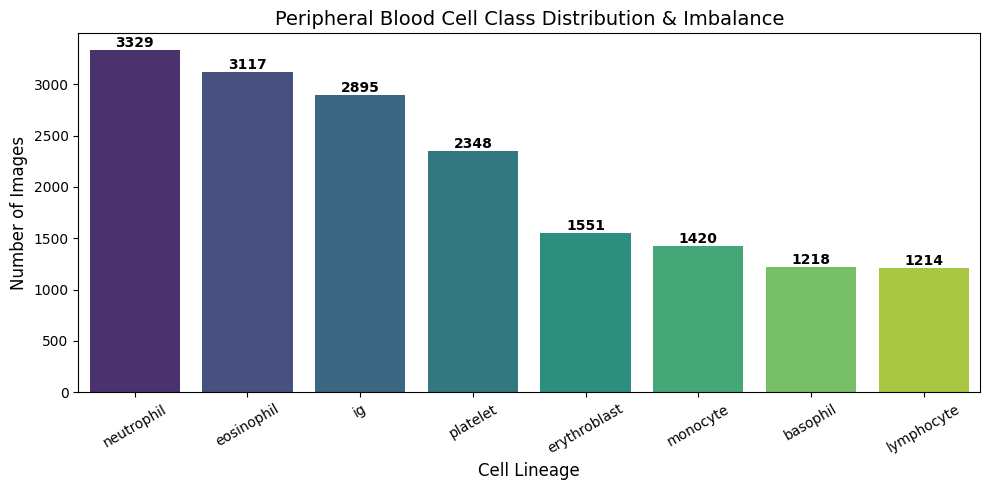

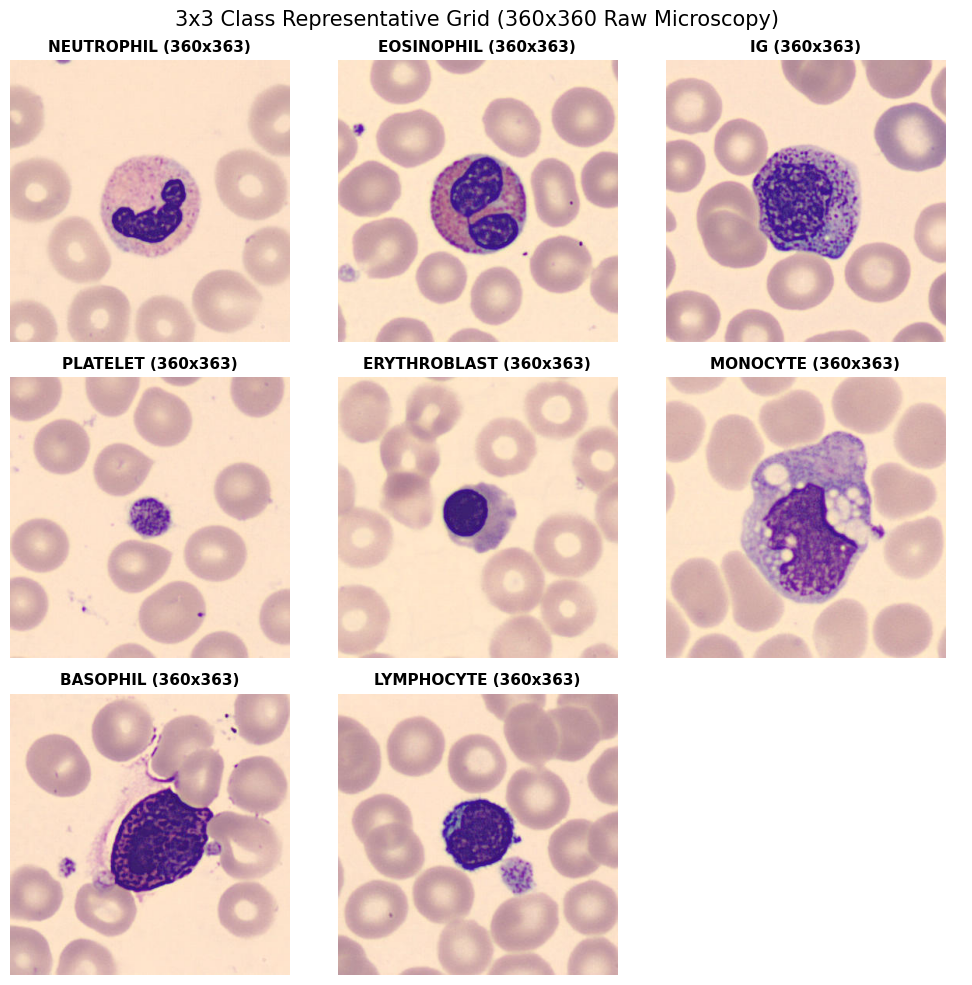

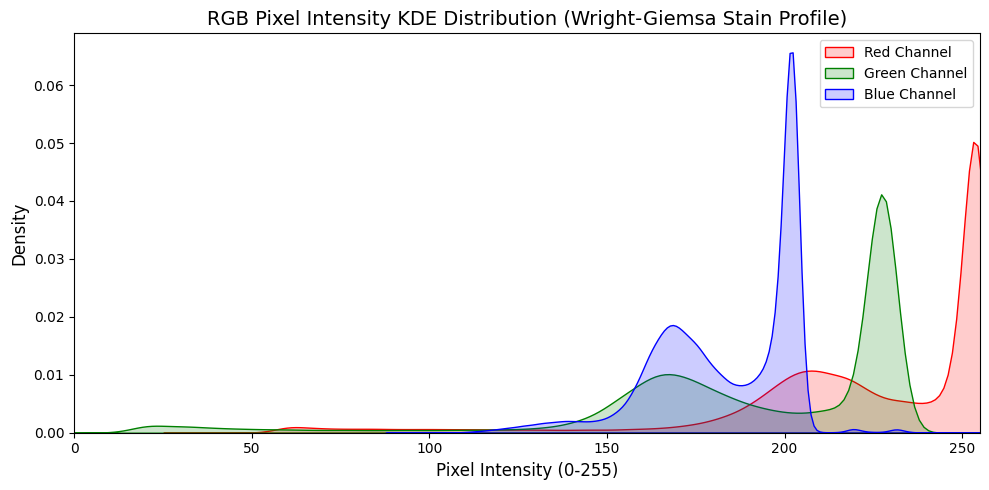


--- 4. Computing t-SNE Embeddings (takes ~30 seconds) ---


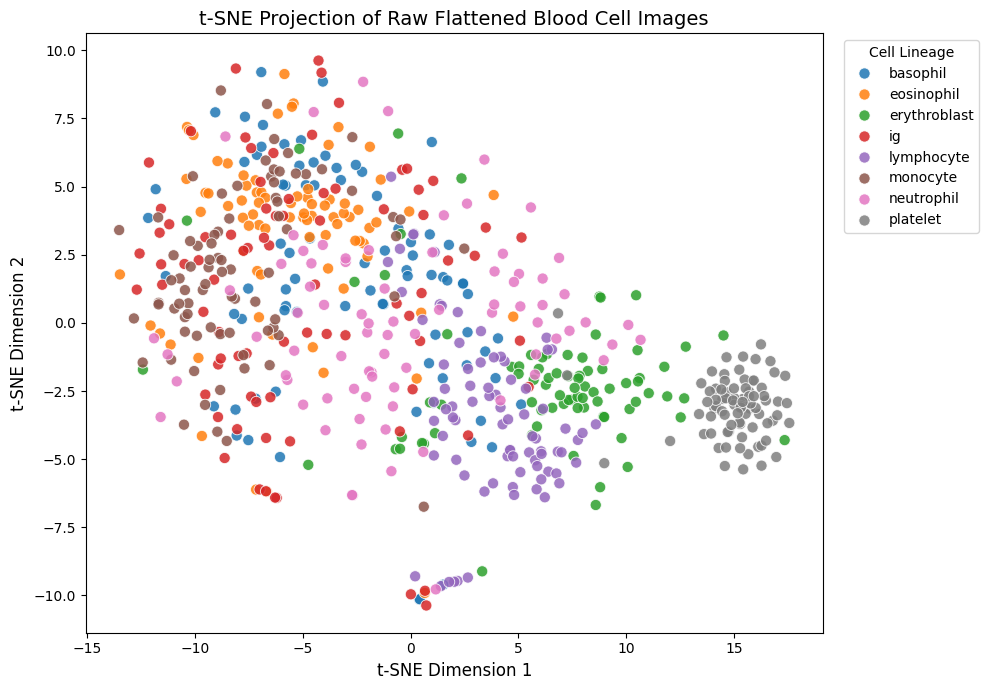

In [4]:
# ==========================================================
# ISSUE #2: EXPLORATORY DATA ANALYSIS (EDA) & CYTOLOGICAL MAPPING
# Zero-Auth Direct Download via KaggleHub Public Mirror (No Google Pop-ups!)
# ==========================================================

import os
import cv2
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# ----------------------------------------------------------
# 0. Download Dataset Directly (Zero Google Auth / Zero 403 Errors)
# ----------------------------------------------------------
# Clean up the 0-byte dummy file from the failed curl attempt
if os.path.exists('/content/PBC_dataset_normal_DIB.zip') and os.path.getsize('/content/PBC_dataset_normal_DIB.zip') < 1000000:
    os.remove('/content/PBC_dataset_normal_DIB.zip')

print("Downloading PBC_dataset_normal_DIB (17,092 images) directly via kagglehub...")
download_root = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset")
print(f"Downloaded to: {download_root}")

target_classes = {'basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet'}
dataset_path = None

for root, dirs, _ in os.walk(download_root):
    if len(target_classes.intersection({d.lower() for d in dirs})) >= 4:
        dataset_path = root
        break

print(f"Verified dataset directory: {dataset_path}")

# ----------------------------------------------------------
# 1. Directory & Integrity Mapping
# ----------------------------------------------------------
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
class_counts = {}
class_files = {}
corrupt_files = 0

for folder_name in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, folder_name)
    if os.path.isdir(folder_path) and not folder_name.startswith('.'):
        valid_imgs = []
        for file in os.listdir(folder_path):
            if file.lower().endswith(valid_extensions) and not file.startswith('.'):
                file_path = os.path.join(folder_path, file)
                if os.path.getsize(file_path) > 0:
                    valid_imgs.append(file_path)
                else:
                    corrupt_files += 1
        if len(valid_imgs) > 0:
            class_counts[folder_name] = len(valid_imgs)
            class_files[folder_name] = valid_imgs

total_images = sum(class_counts.values())
print(f"\nTotal Valid Images: {total_images} | Corrupted/Zero-Byte Files: {corrupt_files}")

df_dist = pd.DataFrame(list(class_counts.items()), columns=['Cell Class', 'Count'])
df_dist = df_dist.sort_values(by='Count', ascending=False).reset_index(drop=True)
min_count = df_dist['Count'].min()
df_dist['Percentage (%)'] = (df_dist['Count'] / total_images * 100).round(2)
df_dist['Imbalance Ratio'] = (df_dist['Count'] / min_count).round(2)
display(df_dist)

# ----------------------------------------------------------
# 2. Class Imbalance Assessment (Bar Chart)
# ----------------------------------------------------------
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_dist, x='Cell Class', y='Count', hue='Cell Class', palette='viridis', legend=False)
plt.title('Peripheral Blood Cell Class Distribution & Imbalance', fontsize=14)
plt.xlabel('Cell Lineage', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=30)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 3. Visual & Chromatic Profiling (3x3 Grid & RGB KDE)
# ----------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle('3x3 Class Representative Grid (360x360 Raw Microscopy)', fontsize=15)

classes_list = df_dist['Cell Class'].tolist()
for i, ax in enumerate(axes.flat):
    if i < len(classes_list):
        cls_name = classes_list[i]
        img_rgb = cv2.cvtColor(cv2.imread(class_files[cls_name][0]), cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.set_title(f"{cls_name.upper()} ({img_rgb.shape[1]}x{img_rgb.shape[0]})", fontsize=11, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
r_vals, g_vals, b_vals = [], [], []
for cls_name, files in class_files.items():
    for fpath in files[:15]:
        img_rgb = cv2.cvtColor(cv2.imread(fpath), cv2.COLOR_BGR2RGB)
        img_small = cv2.resize(img_rgb, (64, 64))
        r_vals.append(img_small[:, :, 0].flatten())
        g_vals.append(img_small[:, :, 1].flatten())
        b_vals.append(img_small[:, :, 2].flatten())

sns.kdeplot(np.concatenate(r_vals), color='red', label='Red Channel', fill=True, alpha=0.2)
sns.kdeplot(np.concatenate(g_vals), color='green', label='Green Channel', fill=True, alpha=0.2)
sns.kdeplot(np.concatenate(b_vals), color='blue', label='Blue Channel', fill=True, alpha=0.2)
plt.title('RGB Pixel Intensity KDE Distribution (Wright-Giemsa Stain Profile)', fontsize=14)
plt.xlabel('Pixel Intensity (0-255)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.xlim(0, 255)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 4. Dimensionality Reduction (t-SNE on Flattened Embeddings)
# ----------------------------------------------------------
print("\n--- 4. Computing t-SNE Embeddings (takes ~30 seconds) ---")
X_flat, y_labels = [], []
for cls_name, files in class_files.items():
    for fpath in files[:80]:
        img_rgb = cv2.cvtColor(cv2.imread(fpath), cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (48, 48))
        X_flat.append(img_resized.flatten())
        y_labels.append(cls_name)

X_flat = np.array(X_flat, dtype=np.float32) / 255.0
X_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(X_flat)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_labels, palette='tab10', s=65, alpha=0.85)
plt.title('t-SNE Projection of Raw Flattened Blood Cell Images', fontsize=14)
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Cell Lineage')
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ==========================================
# CELL 1: SETUP & FILE UPLOAD / EXTRACTION
# ==========================================
import os
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Unzip the dataset
zip_path = '/content/drive/MyDrive/PBC_dataset_normal_DIB.zip'
extract_dir = './extracted_cells'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Dataset extracted successfully!")
else:
    print(f"Please upload your zip file as '{zip_path}' or update the `zip_path` variable.")

# 2. Automatically locate the true data directory (ignoring metadata folders like __MACOSX)
def find_class_data_dir(root_dir):
    for root, dirs, files in os.walk(root_dir):
        # Exclude macOS metadata directories entirely from exploration
        if '__MACOSX' in root:
            continue
        dirs[:] = [d for d in dirs if d != '__MACOSX']

        # Check if the directories inside 'root' contain actual images
        for d in dirs:
            class_path = os.path.join(root, d)
            try:
                any_images = any(f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')) for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f)))
                if any_images:
                    return root
            except Exception:
                continue
    return root_dir

data_dir = find_class_data_dir(extract_dir)
print(f"Data directory: {data_dir}")

Dataset extracted successfully!
Data directory: ./extracted_cells/PBC_dataset_normal_DIB


Total Images Found: 17092

Class Distribution:
basophil        1218
eosinophil      3117
erythroblast    1551
ig              2895
lymphocyte      1214
monocyte        1420
neutrophil      3329
platelet        2348
dtype: int64


/tmp/ipykernel_32770/2193050284.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette='viridis')


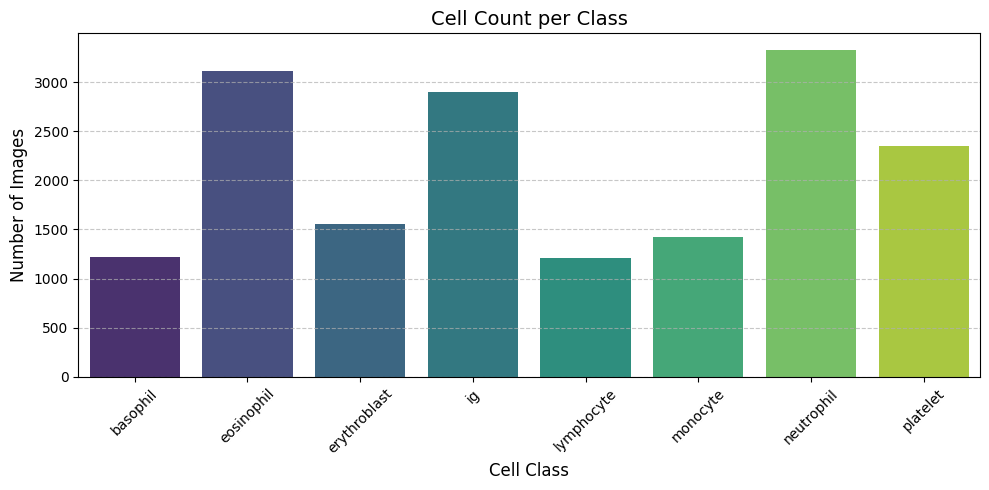

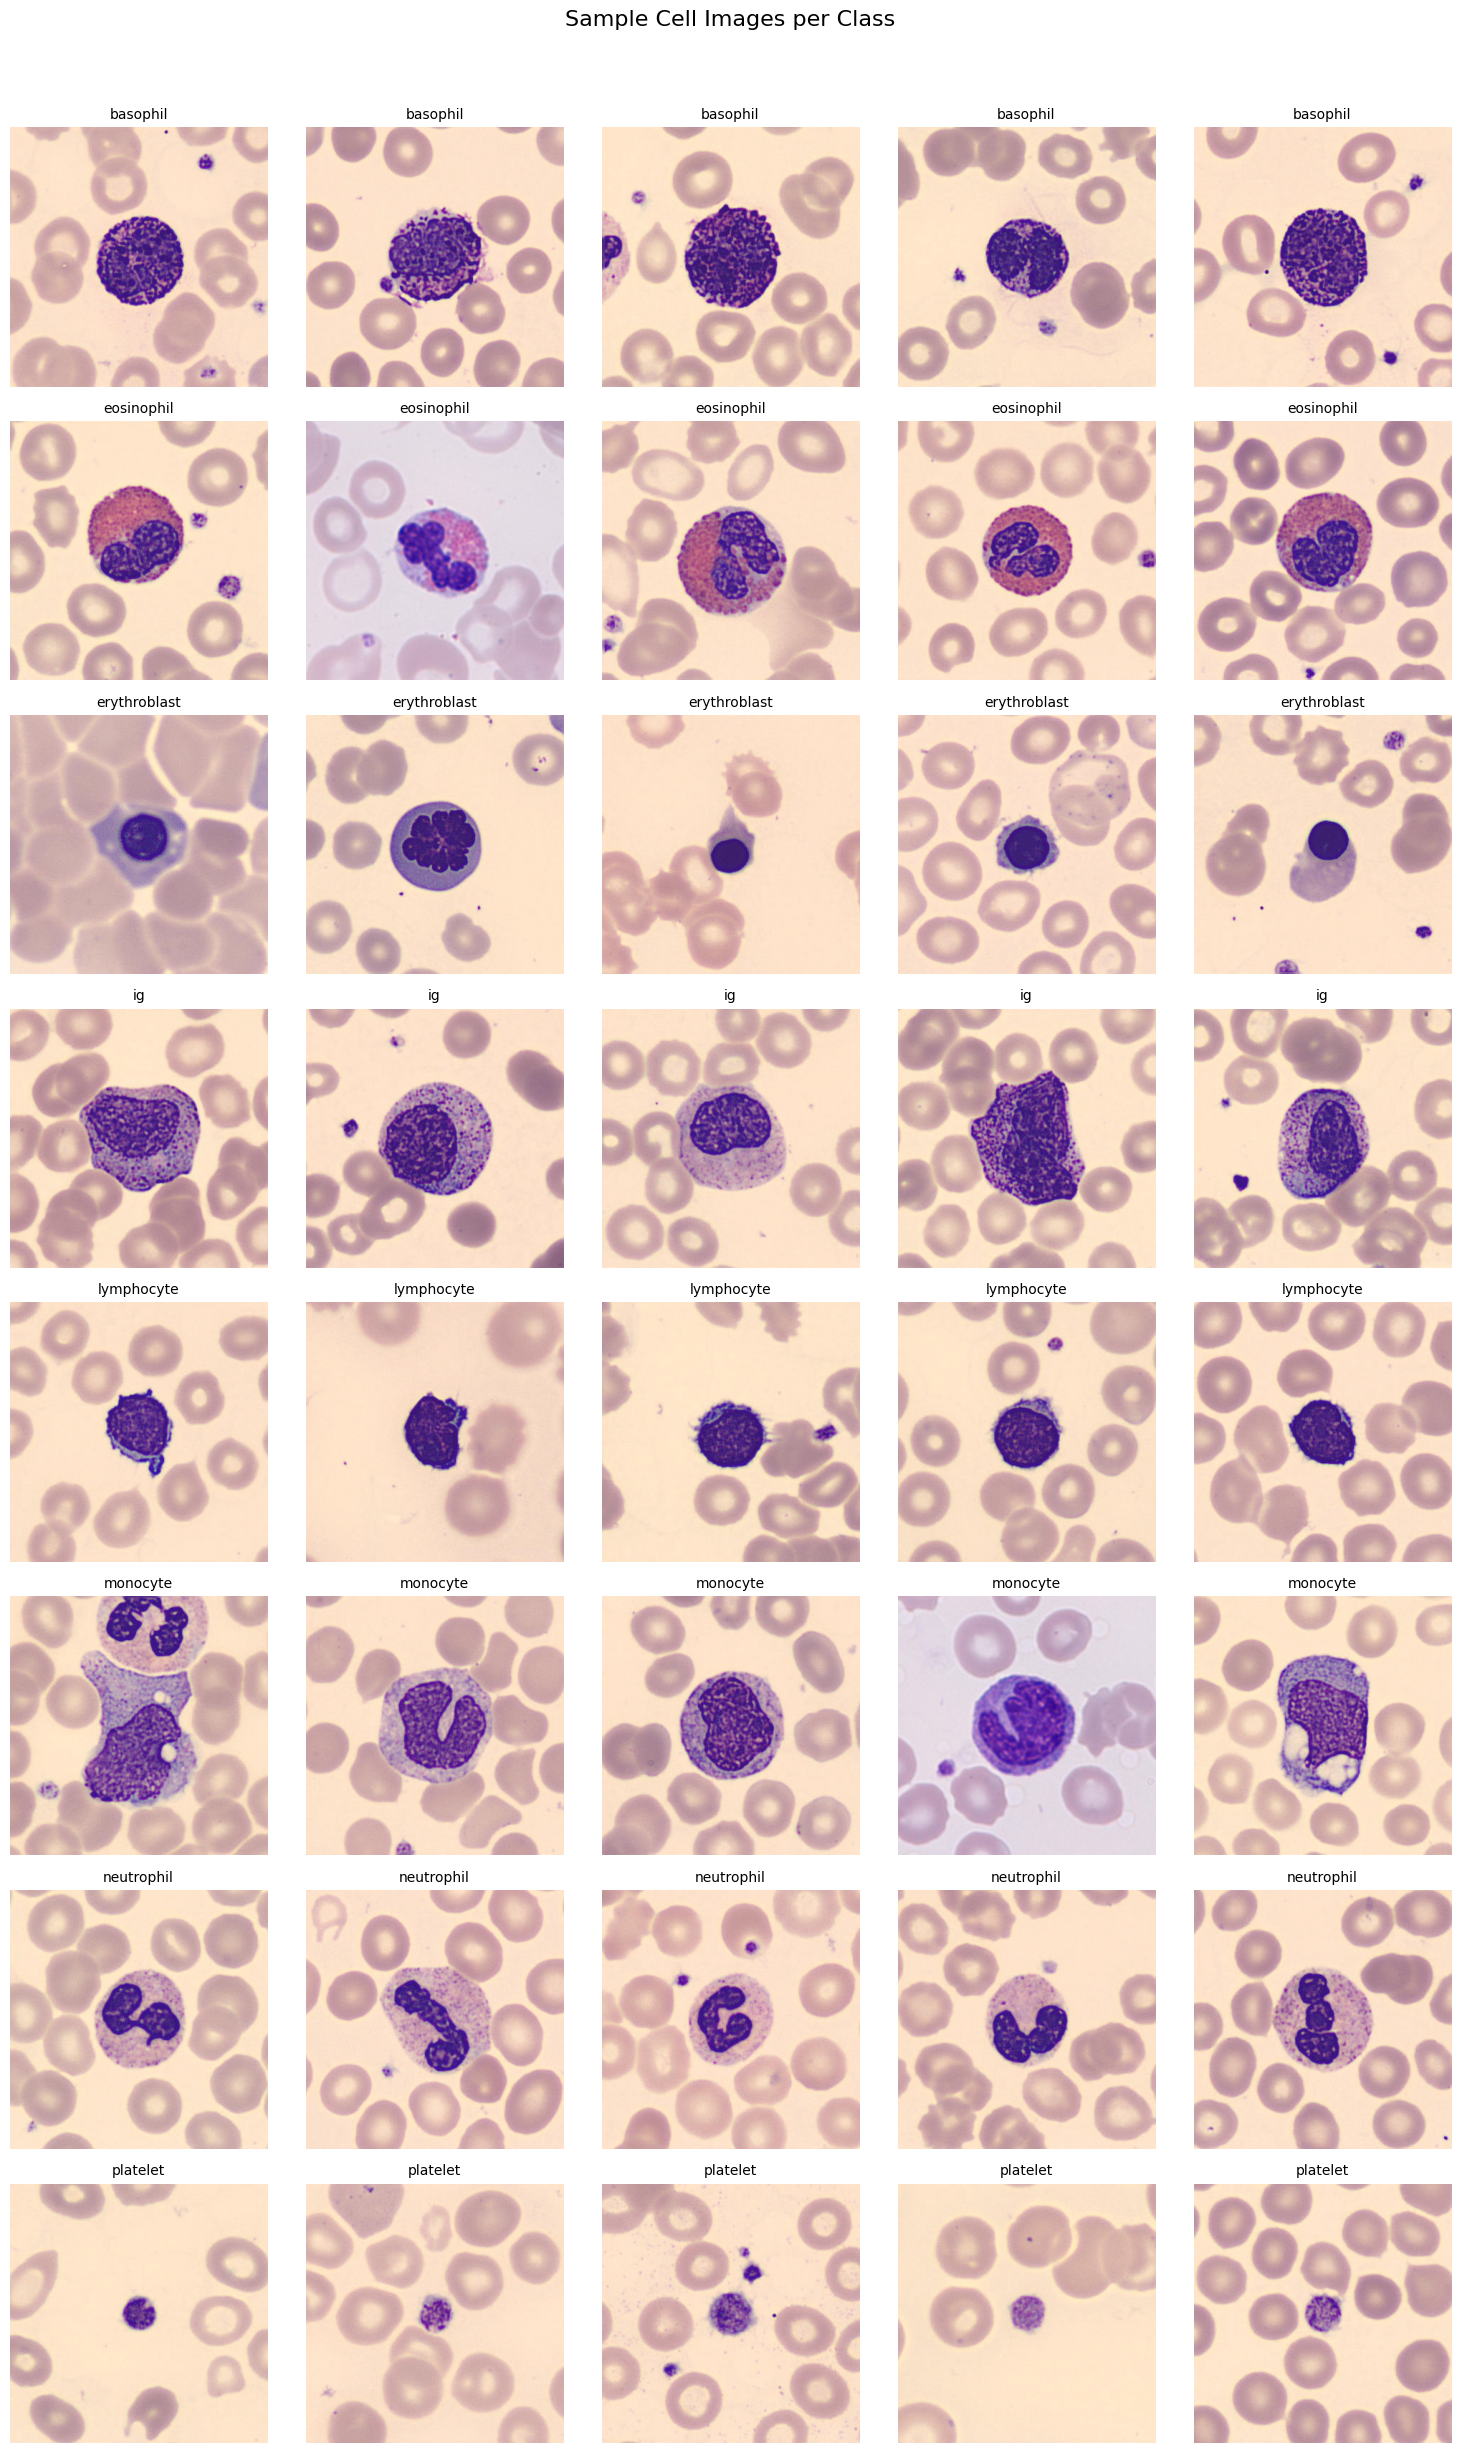

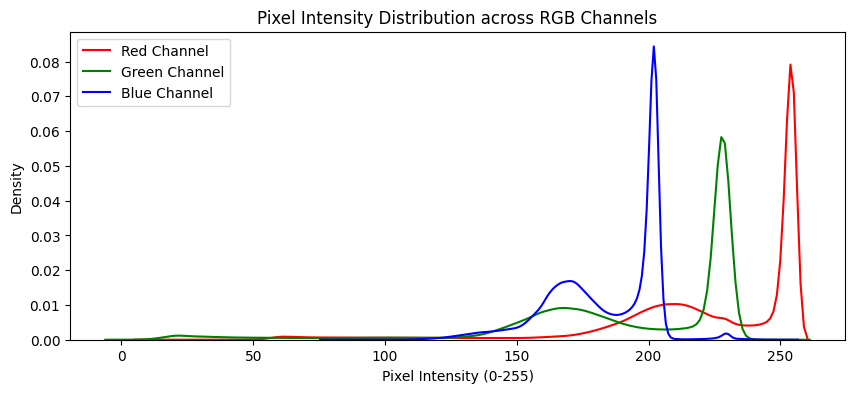

In [ ]:
# ==========================================
# CELL 2: DATASET MAPPING & VISUALIZATION
# ==========================================

# 1. Map class distributions
valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff')
class_counts = {}
image_paths = []
labels = []

for class_name in sorted(os.listdir(data_dir)):
    class_path = os.path.join(data_dir, class_name)
    if os.path.isdir(class_path):
        files = []
        for ext in valid_exts:
            files.extend(glob.glob(os.path.join(class_path, ext)))
            files.extend(glob.glob(os.path.join(class_path, ext.upper())))

        if files:
            class_counts[class_name] = len(files)
            image_paths.extend(files)
            labels.extend([class_name] * len(files))

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

print(f"Total Images Found: {len(df)}")
print("\nClass Distribution:")
print(pd.Series(class_counts))

# 2. Plot Class Distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette='viridis')
plt.title('Cell Count per Class', fontsize=14)
plt.xlabel('Cell Class', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Visualize Sample Images across Classes
unique_classes = list(class_counts.keys())
fig, axes = plt.subplots(len(unique_classes), 5, figsize=(15, 3 * len(unique_classes)))

for idx, cls in enumerate(unique_classes):
    cls_files = df[df['label'] == cls]['image_path'].sample(min(5, class_counts[cls]), random_state=42).values
    for j, img_p in enumerate(cls_files):
        ax = axes[idx, j] if len(unique_classes) > 1 else axes[j]
        img = Image.open(img_p)
        ax.imshow(img)
        ax.set_title(f"{cls}", fontsize=10)
        ax.axis('off')

plt.suptitle('Sample Cell Images per Class', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# 4. Color Channel Analysis (RGB Distribution)
sample_imgs = df.sample(min(50, len(df)), random_state=42)['image_path'].values
r_vals, g_vals, b_vals = [], [], []

for p in sample_imgs:
    img = np.array(Image.open(p).convert('RGB'))
    r_vals.extend(img[:, :, 0].flatten())
    g_vals.extend(img[:, :, 1].flatten())
    b_vals.extend(img[:, :, 2].flatten())

plt.figure(figsize=(10, 4))
sns.kdeplot(r_vals, color='red', label='Red Channel')
sns.kdeplot(g_vals, color='green', label='Green Channel')
sns.kdeplot(b_vals, color='blue', label='Blue Channel')
plt.title('Pixel Intensity Distribution across RGB Channels')
plt.xlabel('Pixel Intensity (0-255)')
plt.legend()
plt.show()

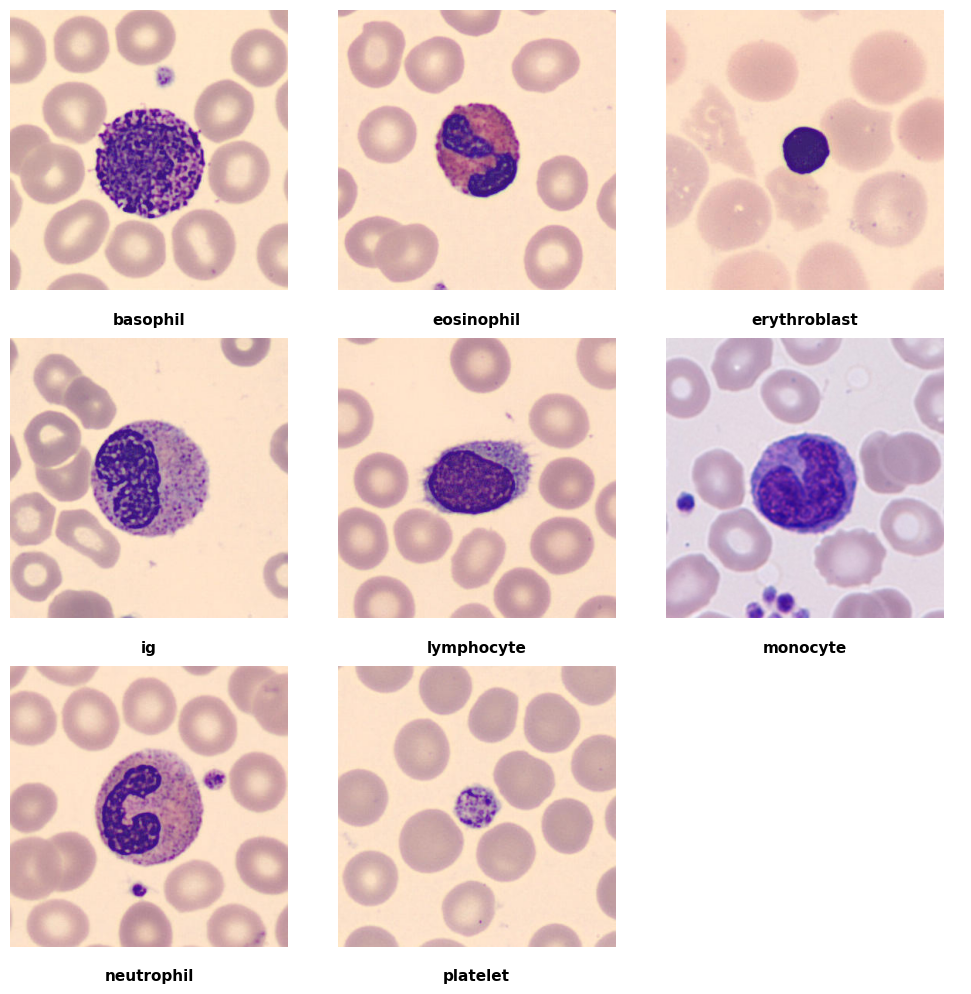

In [ ]:
# ==========================================
# VISUALIZE ONE SAMPLE FROM EACH CLASS (3x3 GRID)
# ==========================================
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Fallback for data_dir
try:
    _current_data_dir = data_dir
except NameError:
    _current_data_dir = './extracted_cells/PBC_dataset_normal_DIB'

# Safely ensure df is defined even if previous cells weren't run recently
try:
    df
except NameError:
    valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
    image_paths = []
    labels = []
    if os.path.exists(_current_data_dir):
        for class_name in sorted(os.listdir(_current_data_dir)):
            class_path = os.path.join(_current_data_dir, class_name)
            if os.path.isdir(class_path):
                files = []
                for ext in valid_exts:
                    files.extend(glob.glob(os.path.join(class_path, ext)))
                    files.extend(glob.glob(os.path.join(class_path, ext.upper())))
                if files:
                    image_paths.extend(files)
                    labels.extend([class_name] * len(files))
    df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# Get one sample image from each class
unique_classes = sorted(df['label'].unique())

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

for idx, cls in enumerate(unique_classes):
    ax = axes[idx]
    # Get a single sample path for this class
    sample_path = df[df['label'] == cls]['image_path'].iloc[0]
    img = Image.open(sample_path)

    ax.imshow(img)
    ax.axis('off')
    ax.text(0.5, -0.08, cls,
                transform=ax.transAxes,
                ha='center', va='top', fontsize=11, fontweight='bold')

# Hide any unused subplots
for idx in range(len(unique_classes), 9):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
from PIL import Image

print("Verifying and cleaning image files...")
corrupt_files_count = 0
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.startswith('.') or not file.lower().endswith(valid_extensions):
            # Remove hidden/system or invalid files
            file_path = os.path.join(root, file)
            try:
                os.remove(file_path)
                print(f"Removed non-image/hidden file: {file_path}")
            except Exception as e:
                print(f"Failed to remove {file_path}: {e}")
            continue

        file_path = os.path.join(root, file)
        try:
            # Try opening and verifying the image structure
            with Image.open(file_path) as img:
                img.verify()  # Verify image integrity

            # Double-check readability by loading pixel data
            with Image.open(file_path) as img:
                img.load()
        except Exception as e:
            print(f"Corrupt file found and removed: {file_path} (Error: {e})")
            try:
                os.remove(file_path)
                corrupt_files_count += 1
            except Exception as delete_error:
                print(f"Failed to delete corrupt file {file_path}: {delete_error}")

print(f"Cleanup complete. Total corrupt files removed: {corrupt_files_count}")

Verifying and cleaning image files...
Removed non-image/hidden file: ./extracted_cells/PBC_dataset_normal_DIB/neutrophil/.DS_169665.jpg
Cleanup complete. Total corrupt files removed: 0


In [ ]:
# ==========================================
# CELL 3: DATA PREPARATION & PIPELINE (SUBSAMPLED)
# ==========================================
import os
import glob
import pandas as pd
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32  # Reduced batch size for smaller datasets
SEED = 42

# Fallback for data_dir
try:
    _current_data_dir = data_dir
except NameError:
    _current_data_dir = './extracted_cells/PBC_dataset_normal_DIB'

# 1. Reconstruct image path DataFrame to create clean sub-samples
valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
image_paths = []
labels = []

if os.path.exists(_current_data_dir):
    for class_name in sorted(os.listdir(_current_data_dir)):
        class_path = os.path.join(_current_data_dir, class_name)
        if os.path.isdir(class_path):
            files = []
            for ext in valid_exts:
                files.extend(glob.glob(os.path.join(class_path, ext)))
                files.extend(glob.glob(os.path.join(class_path, ext.upper())))
            if files:
                image_paths.extend(files)
                labels.extend([class_name] * len(files))

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# 2. Sample exactly 500 training and 100 validation images from each class
train_dfs = []
val_dfs = []

for cls in df['label'].unique():
    cls_df = df[df['label'] == cls].sample(frac=1, random_state=SEED)  # Shuffle
    train_dfs.append(cls_df.iloc[:500])  # Take up to 500 for training
    val_dfs.append(cls_df.iloc[500:600])  # Take next 100 for validation

train_df_sub = pd.concat(train_dfs).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df_sub = pd.concat(val_dfs).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Get class names list and index mapping
class_names = sorted(df['label'].unique())
num_classes = len(class_names)
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print(f"Training samples: {len(train_df_sub)} (500 per class)")
print(f"Validation samples: {len(val_df_sub)} (100 per class)")

# 3. Helper functions to load images dynamically into tf.data pipeline
def load_and_preprocess_image(path, label_name):
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_tensor = tf.image.resize(img_tensor, IMG_SIZE)
    # Map class name label to integer index
    label_idx = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(class_names, list(range(num_classes))),
        default_value=-1
    ).lookup(label_name)
    return img_tensor, label_idx

# Create TensorFlow datasets from dataframe paths & labels
train_ds = tf.data.Dataset.from_tensor_slices((train_df_sub['image_path'].values, train_df_sub['label'].values))
train_ds = train_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df_sub['image_path'].values, val_df_sub['label'].values))
val_ds = val_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

# Data Augmentation Layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
])

# Optimize Performance with caching & prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(len(train_df_sub)).batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)

Training samples: 4000 (500 per class)
Validation samples: 800 (100 per class)


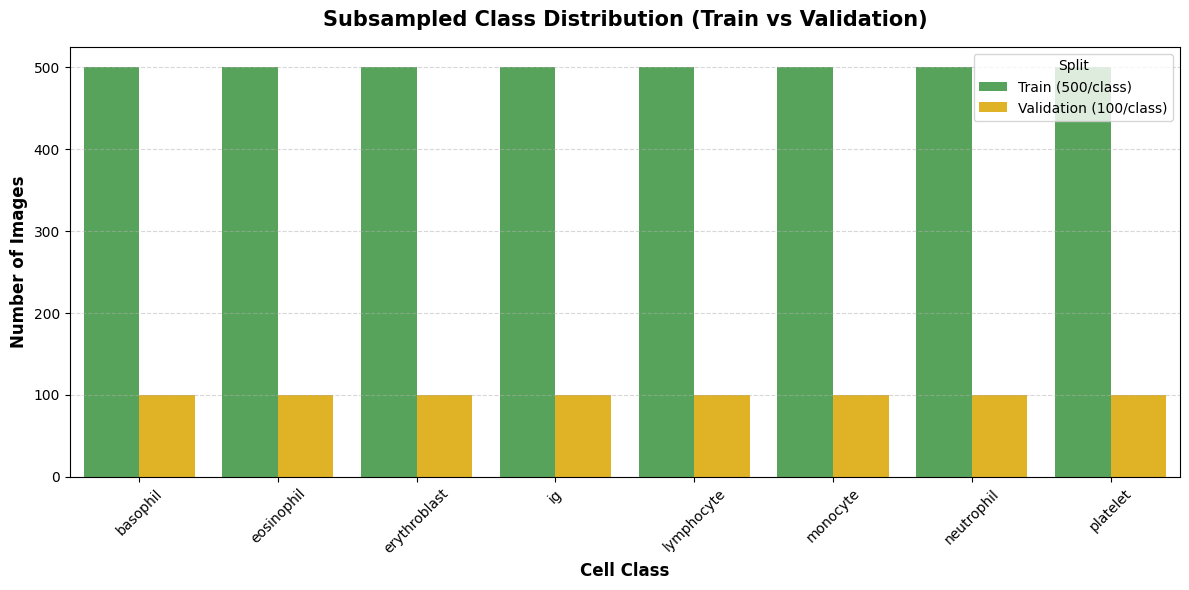

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count occurrences of each class in training and validation sets
train_counts = train_df_sub['label'].value_counts().sort_index()
val_counts = val_df_sub['label'].value_counts().sort_index()

# Create a combined DataFrame for plotting
dist_df = pd.DataFrame({
    'Class': train_counts.index,
    'Train (500/class)': train_counts.values,
    'Validation (100/class)': val_counts.values
}).melt(id_vars='Class', var_name='Split', value_name='Count')

# Plotting the distributions side-by-side
plt.figure(figsize=(12, 6))
sns.barplot(data=dist_df, x='Class', y='Count', hue='Split', palette=['#4CAF50', '#FFC107'])

plt.title('Subsampled Class Distribution (Train vs Validation)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Cell Class', fontsize=12, fontweight='bold')
plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:



# ==========================================
# MODEL 1 : BUILD & TRAIN BASIC CNN MODEL
# ==========================================
model1 = models.Sequential([
    # Input Scaling
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Data Augmentation
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Dense Classifier
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

model1.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)

model1.summary()

# Train Model
EPOCHS = 15
history1 = model1.fit(train_ds, validation_data=val_ds, epochs=15)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,608 (16.36 MB)

 Trainable params: 4,289,160 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 54ms/step - accuracy: 0.2720 - loss: 2.6412 - val_accuracy: 0.1250 - val_loss: 38.5529
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.2925 - loss: 1.7599 - val_accuracy: 0.1262 - val_loss: 11.7340
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.3050 - loss: 1.7424 - val_accuracy: 0.2750 - val_loss: 1.9837
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.3147 - loss: 1.6881 - val_accuracy: 0.3562 - val_loss: 1.8494
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.3440 - loss: 1.6319 - val_accuracy: 0.2463 - val_loss: 1.8593
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.3338 - loss: 1.6714 - val_accuracy: 0.1250 - val_loss: 20.9443
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.3598 - loss: 1.5897 - val_accuracy: 0.1250 - val_loss: 8.6841
Epoch 8/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.3507 - loss: 1.5971 - val_

In [ ]:
# ==========================================
# MODEL 2 : IMPROVED CNN MODEL ARCHITECTURE
# ==========================================

model2 = models.Sequential([
    # Explicit Input Layer (Fixes Keras 3 Warning)
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Input Normalization (0 to 1 range)
    layers.Rescaling(1./255),

    # Data Augmentation Block
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4 (Deeper feature extraction for cell morphology)
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Dense Classifier
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

# Use Learning Rate Scheduler / Reduced Initial LR
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model2.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

# Callbacks for better training performance
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True, verbose=1
    )
]

model2.summary()

# Train Model for 25 Epochs with Early Stopping
history2 = model2.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,587,976 (17.50 MB)

 Trainable params: 4,586,504 (17.50 MB)

 Non-trainable params: 1,472 (5.75 KB)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 65ms/step - accuracy: 0.7427 - loss: 0.7784 - val_accuracy: 0.1250 - val_loss: 9.4470 - learning_rate: 0.0010
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.8708 - loss: 0.4049 - val_accuracy: 0.1250 - val_loss: 9.2209 - learning_rate: 0.0010
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.8852 - loss: 0.3437 - val_accuracy: 0.1737 - val_loss: 4.0847 - learning_rate: 0.0010
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.9072 - loss: 0.2797 - val_accuracy: 0.5412 - val_loss: 1.7790 - learning_rate: 0.0010
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.9197 - loss: 0.2506 - val_accuracy: 0.5500 - val_loss: 1.8753 - learning_rate: 0.0010
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.9252 - loss: 0.2268 - val_accuracy: 0.6325 - val_loss: 1.3628 - learning_rate: 0.0010
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.9295 - loss: 0

In [ ]:
# Calculate current splits based on loaded dataframes and raw dataset counts
total_raw_images = len(df)
train_count = len(train_df_sub)
val_count = len(val_df_sub)
test_count = total_raw_images - (train_count + val_count)

print(f"--- Actual Split Breakdown Used Now ---")
print(f"Train set:      {train_count} images ({train_count / total_raw_images * 100:.2f}% of total dataset)")
print(f"Validation set: {val_count} images ({val_count / total_raw_images * 100:.2f}% of total dataset)")
print(f"Remaining:      {test_count} images ({test_count / total_raw_images * 100:.2f}% of total dataset)")

--- Actual Split Breakdown Used Now ---
Train set:      4000 images (23.40% of total dataset)
Validation set: 800 images (4.68% of total dataset)
Remaining:      12292 images (71.92% of total dataset)


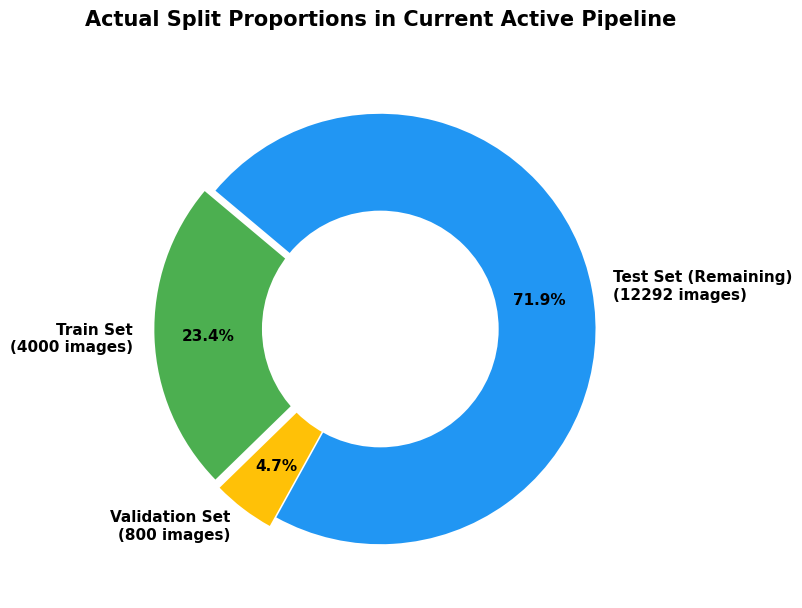

In [ ]:
import matplotlib.pyplot as plt

# Calculate exact counts dynamically
total_raw_images = len(df)
train_count = len(train_df_sub)
val_count = len(val_df_sub)
test_count = total_raw_images - (train_count + val_count)

# Pie chart setup
labels = [
    f'Train Set\n({train_count} images)',
    f'Validation Set\n({val_count} images)',
    f'Test Set (Remaining)\n({test_count} images)'
]
sizes = [train_count, val_count, test_count]
colors = ['#4CAF50', '#FFC107', '#2196F3']
explode = (0.05, 0.05, 0)

plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        startangle=140, pctdistance=0.75, textprops={'fontsize': 11, 'fontweight': 'bold'})

# Transform to Donut Chart
centre_circle = plt.Circle((0,0),0.55,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Actual Split Proportions in Current Active Pipeline', fontsize=15, fontweight='bold', pad=25)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# MODEL 3 - TRANSFER LEARNING (EFFICIENTNETB0)
# ==========================================
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Load Pre-trained Base Model (Freeze initial weights)
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False  # Freeze backbone features

# 2. Build Model Architecture
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = data_augmentation(inputs)

# Note: EfficientNet includes its own internal normalization layer.
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')(x)

model3 = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_Transfer")

# 3. Compile Model
loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=loss_fn,
    metrics=['accuracy']
)

callbacks_m3 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
    )
]

print("--- Phase 1: Training Top Classifier Head ---")
history3_phase1 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_m3
)

# 4. Phase 2: Fine-Tuning Top Layers of Base Model
print("\n--- Phase 2: Fine-Tuning Deep Convolutional Feature Maps ---")
base_model.trainable = True

# Freeze bottom 100 layers and fine-tune top layers only
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a significantly lower learning rate to preserve pre-trained features
model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss_fn,
    metrics=['accuracy']
)

history3_phase2 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_m3
)

# Combine history logs for seamless plotting later
class CombinedHistory:
    def __init__(self, h1, h2):
        self.history = {}
        for key in h1.history.keys():
            self.history[key] = h1.history[key] + h2.history[key]

history3 = CombinedHistory(history3_phase1, history3_phase2)

--- Phase 1: Training Top Classifier Head ---
Epoch 1/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.5585 - loss: 1.3578 - val_accuracy: 0.7075 - val_loss: 0.9591 - learning_rate: 0.0010
Epoch 2/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.6960 - loss: 0.9151 - val_accuracy: 0.7550 - val_loss: 0.7089 - learning_rate: 0.0010
Epoch 3/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7230 - loss: 0.8005 - val_accuracy: 0.7725 - val_loss: 0.6206 - learning_rate: 0.0010
Epoch 4/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.7490 - loss: 0.7439 - val_accuracy: 0.7950 - val_loss: 0.5987 - learning_rate: 0.0010
Epoch 5/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.7492 - loss: 0.7183 - val_accuracy: 0.7975 - val_loss: 0.5306 - learning_rate: 0.0010
Epoch 6/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.7722 - loss: 0.6555 - val_accuracy: 0.7975 - val_loss: 0.5648 - learning_rate: 0.0010
Epoch 7/12
125/125 ━━━━━━━━━━━━━━━━

In [ ]:
# # ==========================================
# # MODEL 3 V2 - FINE-TUNED EFFICIENTNETB0
# # ==========================================
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras import layers, models
# from sklearn.utils.class_weight import compute_class_weight

# # 1. Resize pipeline to 224x224 for EfficientNet optimal receptive field
# NEW_SIZE = (224, 224)

# train_ds_224 = tf.keras.utils.image_dataset_from_directory(
#     data_dir,
#     validation_split=0.2,
#     subset="training",
#     seed=42,
#     image_size=NEW_SIZE,
#     batch_size=32
# )

# val_ds_224 = tf.keras.utils.image_dataset_from_directory(
#     data_dir,
#     validation_split=0.2,
#     subset="validation",
#     seed=42,
#     image_size=NEW_SIZE,
#     batch_size=32
# )

# train_ds_224 = train_ds_224.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
# val_ds_224 = val_ds_224.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# # 2. Separate Data Augmentation for 224x224 input shape
# data_augmentation_224 = tf.keras.Sequential([
#     layers.RandomFlip("horizontal_and_vertical"),
#     layers.RandomRotation(0.2),
#     layers.RandomZoom(0.1),
# ], name="data_augmentation_224")

# # 3. Compute Class Weights to balance difficult classes
# y_train_labels = []
# for _, labels_b in train_ds_224:
#     y_train_labels.extend(labels_b.numpy())

# class_weights = compute_class_weight(
#     class_weight='balanced',
#     classes=np.unique(y_train_labels),
#     y=y_train_labels
# )
# class_weight_dict = dict(enumerate(class_weights))

# # Boost weights slightly for historically struggling classes (Erythroblast, IG, Monocyte)
# for idx, name in enumerate(class_names):
#     if name in ['erythroblast', 'ig', 'monocyte']:
#         class_weight_dict[idx] *= 1.3

# # 4. Build Model Architecture
# base_model_v2 = tf.keras.applications.EfficientNetB0(
#     include_top=False,
#     weights='imagenet',
#     input_shape=(NEW_SIZE[0], NEW_SIZE[1], 3)
# )

# # Unfreeze ONLY the last 15 layers for fine-grained tuning
# base_model_v2.trainable = True
# for layer in base_model_v2.layers[:-15]:
#     layer.trainable = False

# inputs = layers.Input(shape=(NEW_SIZE[0], NEW_SIZE[1], 3))
# x = data_augmentation_224(inputs)
# x = base_model_v2(x, training=False)
# x = layers.GlobalAveragePooling2D()(x)
# x = layers.BatchNormalization()(x)
# x = layers.Dropout(0.4)(x)
# x = layers.Dense(256, activation='relu')(x)
# x = layers.BatchNormalization()(x)
# x = layers.Dropout(0.3)(x)
# outputs = layers.Dense(num_classes, activation='softmax')(x)

# model3 = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_FineTuned")

# # 5. Compile with a conservative, stable Learning Rate
# model3.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
#     loss=tf.keras.losses.SparseCategoricalCrossentropy(),
#     metrics=['accuracy']
# )

# callbacks_v2 = [
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6, verbose=1
#     ),
#     tf.keras.callbacks.EarlyStopping(
#         monitor='val_loss', patience=7, restore_best_weights=True, verbose=1
#     )
# ]

# # 6. Train Fine-Tuned Model
# history3 = model3.fit(
#     train_ds_224,
#     validation_data=val_ds_224,
#     epochs=20,
#     class_weight=class_weight_dict,
#     callbacks=callbacks_v2
# )

NameError: name 'data_dir' is not defined

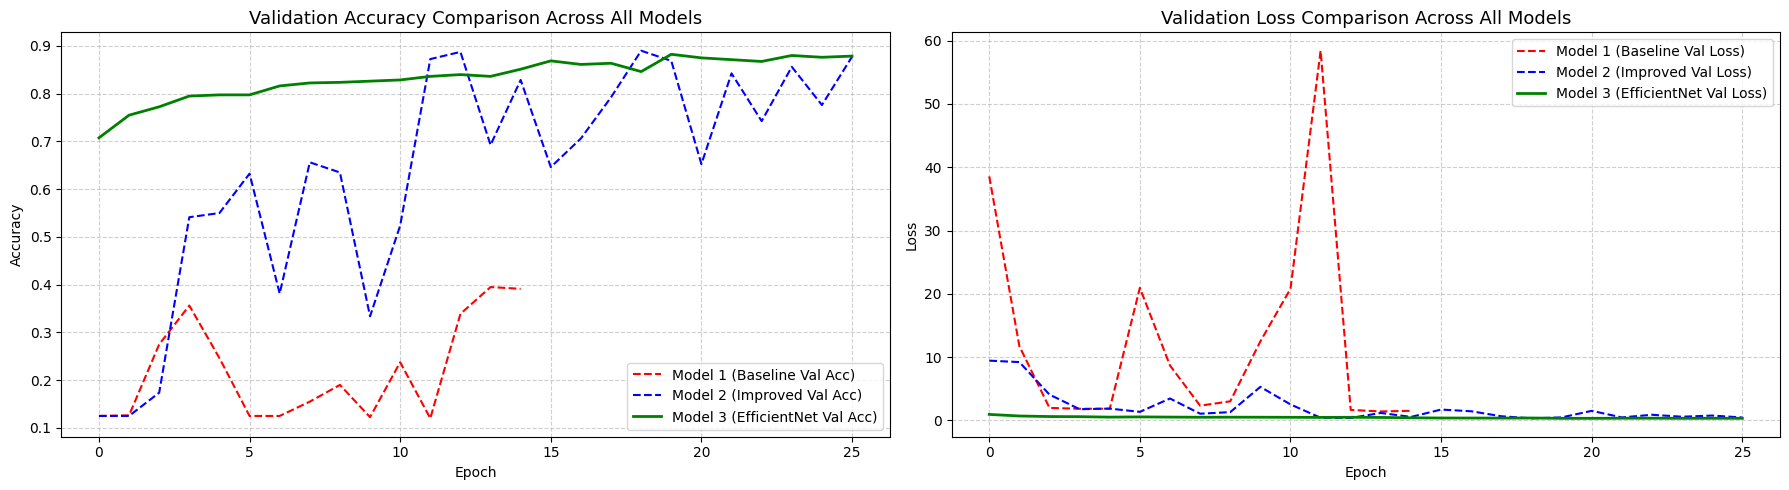

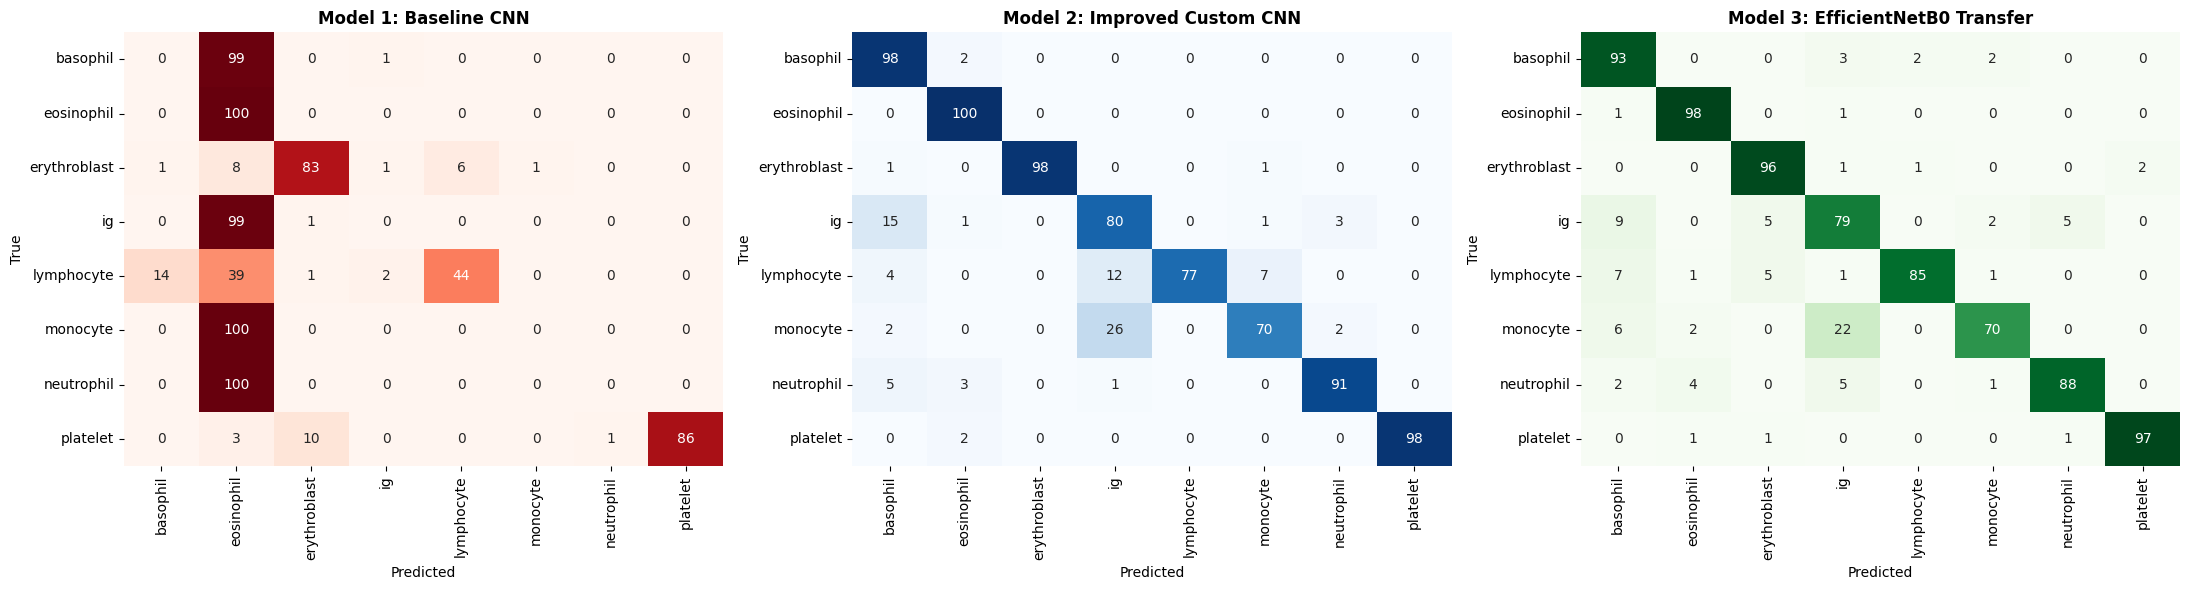

              MODEL 1 (BASELINE CNN) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    basophil       0.00      0.00      0.00       100
  eosinophil       0.18      1.00      0.31       100
erythroblast       0.87      0.83      0.85       100
          ig       0.00      0.00      0.00       100
  lymphocyte       0.88      0.44      0.59       100
    monocyte       0.00      0.00      0.00       100
  neutrophil       0.00      0.00      0.00       100
    platelet       1.00      0.86      0.92       100

    accuracy                           0.39       800
   macro avg       0.37      0.39      0.33       800
weighted avg       0.37      0.39      0.33       800

          MODEL 2 (IMPROVED CUSTOM CNN) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    basophil       0.78      0.98      0.87       100
  eosinophil       0.93      1.00      0.96       100
erythroblast       1.00      0.98      0.99       100
          i

In [ ]:
# ==========================================
# CELL 5: 3-WAY MODEL PERFORMANCE COMPARISON
# ==========================================
import matplotlib.pyplot as plt
# 1. Overlay Training & Validation Curves for All 3 Models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))

# Accuracy Comparison Plot
ax1.plot(history1.history['val_accuracy'], label='Model 1 (Baseline Val Acc)', color='red', linestyle='--')
ax1.plot(history2.history['val_accuracy'], label='Model 2 (Improved Val Acc)', color='blue', linestyle='--')
ax1.plot(history3.history['val_accuracy'], label='Model 3 (EfficientNet Val Acc)', color='green', linewidth=2)
ax1.set_title('Validation Accuracy Comparison Across All Models', fontsize=13)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Loss Comparison Plot
ax2.plot(history1.history['val_loss'], label='Model 1 (Baseline Val Loss)', color='red', linestyle='--')
ax2.plot(history2.history['val_loss'], label='Model 2 (Improved Val Loss)', color='blue', linestyle='--')
ax2.plot(history3.history['val_loss'], label='Model 3 (EfficientNet Val Loss)', color='green', linewidth=2)
ax2.set_title('Validation Loss Comparison Across All Models', fontsize=13)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Extract Validation Predictions for All 3 Models
def get_predictions(model_obj):
    y_true, y_pred = [], []
    for images, labels_batch in val_ds:
        preds = model_obj.predict(images, verbose=0)
        y_true.extend(labels_batch.numpy())
        if num_classes > 2:
            y_pred.extend(np.argmax(preds, axis=1))
        else:
            y_pred.extend((preds > 0.5).astype(int).flatten())
    return np.array(y_true), np.array(y_pred)

y_true1, y_pred1 = get_predictions(model1)
y_true2, y_pred2 = get_predictions(model2)
y_true3, y_pred3 = get_predictions(model3)

# 3. Plot Confusion Matrices Side-by-Side (3 Models)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

cm1 = confusion_matrix(y_true1, y_pred1)
sns.heatmap(cm1, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_names, yticklabels=class_names, ax=ax1, cbar=False)
ax1.set_title('Model 1: Baseline CNN', fontsize=12, fontweight='bold')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('True')

cm2 = confusion_matrix(y_true2, y_pred2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax2, cbar=False)
ax2.set_title('Model 2: Improved Custom CNN', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('True')

cm3 = confusion_matrix(y_true3, y_pred3)
sns.heatmap(cm3, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=ax3, cbar=False)
ax3.set_title('Model 3: EfficientNetB0 Transfer', fontsize=12, fontweight='bold')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('True')

plt.tight_layout()
plt.show()

# 4. Print Classification Reports for All Models
print("=" * 65)
print("              MODEL 1 (BASELINE CNN) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true1, y_pred1, target_names=class_names, zero_division=0))

print("=" * 65)
print("          MODEL 2 (IMPROVED CUSTOM CNN) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true2, y_pred2, target_names=class_names, zero_division=0))

print("=" * 65)
print("        MODEL 3 (EFFICIENTNETB0 TRANSFER) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true3, y_pred3, target_names=class_names, zero_division=0))